# Gaussian mixture model

In [4]:
print("What is gaussian mixture model")
print("Gaussian Mixture Model (GMM) is an unsupervised probabilistic clustering algorithm that assumes \n the data is generated from a mixture of several Gaussian (normal) distributions.")

What is gaussian mixture model
Gaussian Mixture Model (GMM) is an unsupervised probabilistic clustering algorithm that assumes 
 the data is generated from a mixture of several Gaussian (normal) distributions.


# For more info click in the link below 

https://docs.google.com/document/d/1KgVzlkNbx1MDaAx5sp81SoeptawzgORMeKU2x_4kLD0/edit?usp=sharing

# Notes and interview Q and A

https://docs.google.com/document/d/13XH2D0PKfF_wEPttMwnrYX9QAdiuGEekNLcEwx7XOe0/edit?usp=sharing

# Coding

# Import libraries 


In [1]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# Iris dataset → built-in clustering dataset
from sklearn.datasets import load_iris

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# GaussianMixture → Gaussian Mixture Model
from sklearn.mixture import GaussianMixture

# Silhouette Score → evaluates cluster separation
from sklearn.metrics import silhouette_score

# load the dataset 


In [2]:
iris = load_iris()                       # Loads the Iris dataset

X = iris.data                            # Features used by GMM

y = iris.target                          # True labels, NOT used for training

In [3]:
# Check 

print(X.shape)

(150, 4)


In [4]:
# Scaler the features 

# GMM can be affected by features scaler, so standardization is usefull . 


scaler = StandardScaler()                # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                     # Standardizes all four features
)

In [5]:
# Create the GMM 
# Because we want to model tree gaussian components 

gmm = GaussianMixture(
    n_components=3,                       # Number of Gaussian distributions/components
    covariance_type="full",               # Each component gets its own full covariance matrix
    n_init=10,                            # Run EM from 10 different initializations
    random_state=42                       # Makes the result reproducible
)

In [6]:
# Trian GMM
gmm.fit(
    X_scaled                             # Learn Gaussian distributions from the feature data
)

,"n_components n_components: int, default=1The number of mixture components.",3
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [7]:
# Predict cluster assignments 


clusters = gmm.predict(
    X_scaled                             # Assign each point to its most probable component
)

print(clusters[:20])                     # Display the first 20 cluster assignments


[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [11]:
probabilities = gmm.predict_proba(
    X_scaled                             # Calculate probability of each component for every point
)

print(probabilities[:5])

# GMM naturally perform soft clustering 

[[6.68458864e-44 1.00000000e+00 7.44269825e-35]
 [6.88281903e-31 1.00000000e+00 2.97316198e-28]
 [7.26674155e-36 1.00000000e+00 4.82530460e-30]
 [1.16681891e-31 1.00000000e+00 3.06088222e-26]
 [2.43353714e-46 1.00000000e+00 3.11573125e-35]]


In [12]:
# Evaluate the clustering 
# We can use the silhouette score 


probabilities = gmm.predict_proba(
    X_scaled                             # Calculate probability of each component for every point
)

print(probabilities[:5])

[[6.68458864e-44 1.00000000e+00 7.44269825e-35]
 [6.88281903e-31 1.00000000e+00 2.97316198e-28]
 [7.26674155e-36 1.00000000e+00 4.82530460e-30]
 [1.16681891e-31 1.00000000e+00 3.06088222e-26]
 [2.43353714e-46 1.00000000e+00 3.11573125e-35]]


# Log-likelihood

# GMM tries to maximise the probability of the observed data under the gaussian mixture model

In [13]:
log_likelihood = gmm.score(
    X_scaled                             # Calculate average log-likelihood of the data
)

print("Average Log-Likelihood:", log_likelihood)

Average Log-Likelihood: -1.9369263973830528


In [15]:
# AIC and BIC

aic = gmm.aic(
    X_scaled                             # Calculate Akaike Information Criterion
)

bic = gmm.bic(
    X_scaled                             # Calculate Bayesian Information Criterion
)

print("AIC:", aic)
print("BIC:", bic)

# Lower is better for both 

AIC: 669.0779192149158
BIC: 801.5458721551511


In [16]:
# Experiment with number of components 
# This is the most important GMM hyperparameter 

components = range(1, 8)                 # Test 1 through 7 Gaussian components

aic_scores = []                          # Store AIC values

bic_scores = []                          # Store BIC values

silhouette_scores = []                   # Store Silhouette Scores

for n in components:

    model = GaussianMixture(
        n_components=n,                  # Try this number of Gaussian components
        covariance_type="full",           # Full covariance for each component
        n_init=10,                        # Multiple initializations
        random_state=42                   # Reproducibility
    )

    model.fit(
        X_scaled                           # Train GMM
    )

    aic_scores.append(
        model.aic(X_scaled)                # Store AIC
    )

    bic_scores.append(
        model.bic(X_scaled)                # Store BIC
    )

    if n > 1:

        labels = model.predict(
            X_scaled                       # Get cluster assignments
        )

        silhouette_scores.append(
            silhouette_score(
                X_scaled,                  # Dataset
                labels                     # Cluster assignments
            )
        )

    else:

        silhouette_scores.append(
            np.nan                         # Silhouette requires at least 2 clusters
        )

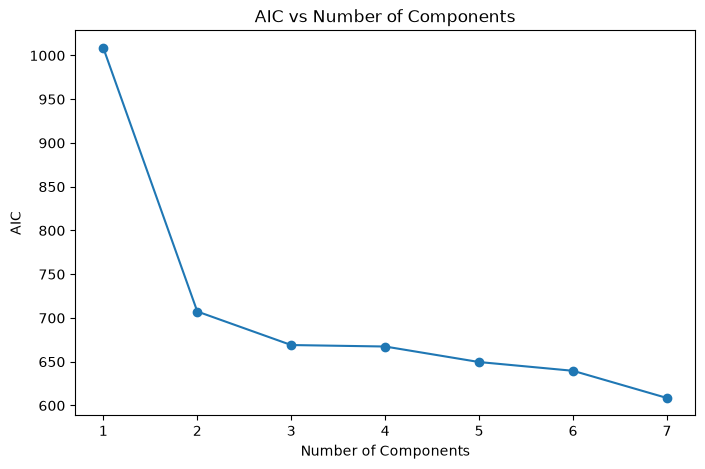

In [18]:
# Plot AIC
plt.figure(figsize=(8, 5))

plt.plot(
    components,                           # Number of components
    aic_scores,                            # AIC values
    marker="o"                            # Show each value
)

plt.xlabel("Number of Components")
plt.ylabel("AIC")
plt.title("AIC vs Number of Components")

plt.show()


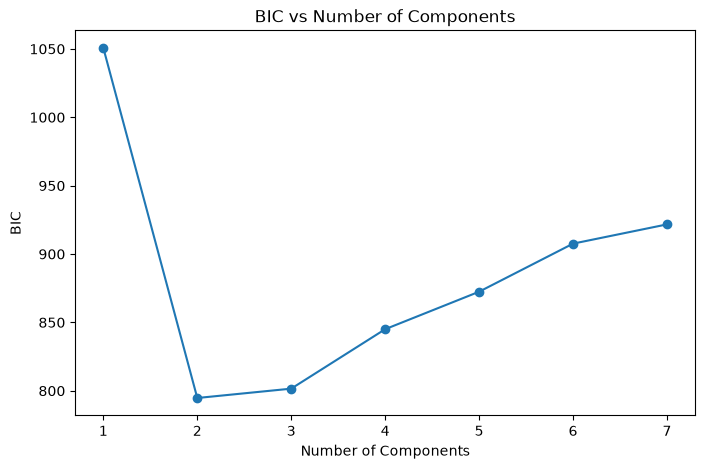

In [19]:
# Plot BIC

plt.figure(figsize=(8, 5))

plt.plot(
    components,                           # Number of components
    bic_scores,                            # BIC values
    marker="o"                            # Show each value
)

plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("BIC vs Number of Components")

plt.show()

In [20]:
# Compare them 

covariance_types = [
    "full",
    "tied",
    "diag",
    "spherical"
]

for covariance in covariance_types:

    model = GaussianMixture(
        n_components=3,                   # Keep number of components fixed
        covariance_type=covariance,        # Test a different covariance structure
        n_init=10,                        # Multiple initializations
        random_state=42                   # Reproducibility
    )

    model.fit(
        X_scaled                           # Train GMM
    )

    labels = model.predict(
        X_scaled                           # Obtain cluster assignments
    )

    score = silhouette_score(
        X_scaled,                          # Dataset
        labels                             # Cluster assignments
    )

    print(
        f"{covariance}: {score:.3f}"
    )

full: 0.374
tied: 0.391
diag: 0.413
spherical: 0.457


In [21]:
# Visualize GMM clusters


final_gmm = GaussianMixture(
    n_components=3,                        # Final number of Gaussian components
    covariance_type="full",                # Flexible covariance structure
    n_init=10,                             # Multiple initializations
    random_state=42                        # Reproducibility
)

final_clusters = final_gmm.fit_predict(
    X_scaled                              # Train GMM and assign clusters
)


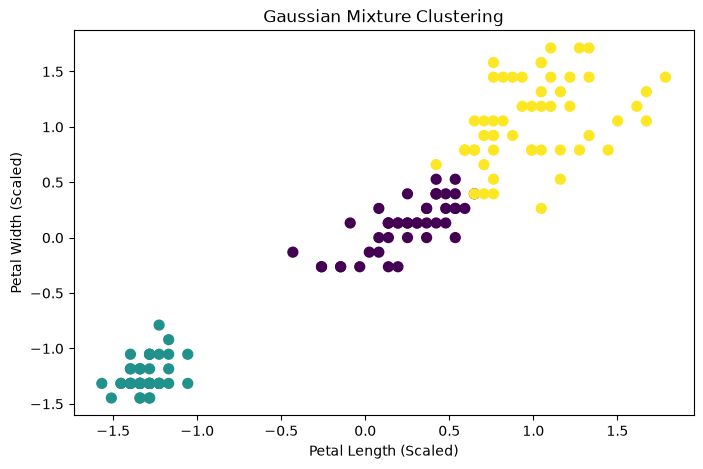

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 2],                        # Petal length
    X_scaled[:, 3],                        # Petal width
    c=final_clusters,                      # Color by GMM cluster
    s=50                                   # Point size
)

plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")
plt.title("Gaussian Mixture Clustering")

plt.show()